## Feature Exploration

In [51]:
from pathlib import Path
import sys
from collections import deque
from hashlib import sha256
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / 'data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    
from src.preprocessing import (
    load_transactions, validate_transactions, sort_transactions, add_temporal_features,
    add_amount_features, add_behavior_features, add_geographic_features,
    add_merchant_features, add_demographic_features,
)
from src.preprocessing import quality_filter, mutual_information_selection

# 1. Data Loading and Validation

In [52]:
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'case_cc_fraud.csv'

df, loaded_count, duplicate_count = load_transactions(DATA_PATH)

print(f'Loaded {loaded_count:,} transactions.')
print(f'Exact duplicate rows: {duplicate_count:,}')
print(f'Transactions after removing exact duplicates: {len(df):,}')

Loaded 1,852,394 transactions.
Exact duplicate rows: 0
Transactions after removing exact duplicates: 1,852,394


### Validation

In [53]:
df = validate_transactions(df)

print('Transaction date range:', df['trans_date_trans_time'].min(), 'to', df['trans_date_trans_time'].max())
print('Input sorted by time:', df['trans_date_trans_time'].is_monotonic_increasing)

Transaction date range: 2019-01-01 00:00:18 to 2020-12-31 23:59:34
Input sorted by time: False


# 2. Feature Engineering

In [54]:
df = sort_transactions(df)

### Temporal Features

In [55]:
df = add_temporal_features(df)

display(df[['hour', 'day_of_week', 'is_weekend', 'is_night', 'is_evening',
            'month', 'day_of_month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']].describe())

,hour,day_of_week,is_weekend,is_night,is_evening,month,day_of_month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
count,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06
mean,1.280612e+01,2.967456e+00,3.276322e-01,1.963810e-01,3.053217e-01,7.152067e+00,1.585076e+01,-1.370118e-01,-1.459222e-02,-7.464929e-02,1.472190e-01
std,6.815753e+00,2.197983e+00,4.693501e-01,3.972601e-01,4.605437e-01,3.424954e+00,8.876245e+00,6.930332e-01,7.076160e-01,6.850874e-01,7.095138e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,-1.000000e+00,-1.000000e+00,-9.749279e-01,-9.009689e-01
25%,7.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,8.000000e+00,-8.660254e-01,-7.071068e-01,-7.818315e-01,-2.225209e-01
50%,1.400000e+01,3.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e+00,1.600000e+01,-2.588190e-01,-1.836970e-16,0.000000e+00,6.234898e-01
75%,1.900000e+01,5.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+01,2.400000e+01,5.000000e-01,7.071068e-01,4.338837e-01,6.234898e-01
max,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.200000e+01,3.100000e+01,1.000000e+00,1.000000e+00,9.749279e-01,1.000000e+00


### Transaction Amount Features

In [56]:
df = add_amount_features(df)

display(df[['log_amt', 'customer_history_count', 'customer_avg_amt', 'customer_median_amt',
            'customer_max_amt', 'customer_std_amt', 'amount_vs_avg', 'amount_diff_from_avg',
            'amount_vs_median', 'amount_zscore']].describe())

,log_amt,customer_history_count,customer_avg_amt,customer_median_amt,customer_max_amt,customer_std_amt,amount_vs_avg,amount_diff_from_avg,amount_vs_median,amount_zscore
count,1.852394e+06,1.852394e+06,1.851395e+06,1.851395e+06,1.851395e+06,1.850396e+06,1.851395e+06,1.851395e+06,1.851395e+06,1.850396e+06
mean,3.531722e+00,1.298901e+03,7.028844e+01,4.531420e+01,2.657446e+03,1.349794e+02,1.013245e+00,-2.382734e-01,1.615141e+00,2.127240e-02
std,1.288350e+00,9.694531e+02,1.982252e+01,1.827349e+01,2.961828e+03,7.990762e+01,2.592547e+00,1.585153e+02,4.277390e+00,2.612815e+00
min,6.931472e-01,0.000000e+00,1.030000e+00,1.030000e+00,1.030000e+00,6.363961e-02,2.176430e-03,-1.430420e+03,2.176430e-03,-1.308383e+03
25%,2.364620e+00,5.090000e+02,5.862289e+01,3.628000e+01,1.087530e+03,9.525108e+01,1.560888e-01,-5.206971e+01,2.578648e-01,-4.183189e-01
50%,3.880532e+00,1.109000e+03,6.491312e+01,4.090500e+01,1.649720e+03,1.178310e+02,6.677805e-01,-2.413372e+01,9.991309e-01,-1.864998e-01
75%,4.432007e+00,1.917000e+03,8.362824e+01,5.291000e+01,3.154710e+03,1.476746e+02,1.198126e+00,1.300743e+01,1.877108e+00,1.058223e-01
max,1.027332e+01,4.391000e+03,1.433540e+03,1.433540e+03,2.894890e+04,2.708840e+03,6.763881e+02,2.888934e+04,8.557099e+02,1.323901e+03


### Customer Behavioral Features

In [57]:
df = add_behavior_features(df)

display(df[['tx_count_1h', 'tx_count_24h', 'tx_count_7d', 'tx_count_30d',
            'tx_amount_sum_1h', 'tx_amount_sum_24h', 'tx_amount_sum_7d', 'tx_amount_sum_30d',
            'tx_amount_avg_30d', 'time_since_last_tx', 'unique_merchants_7d',
            'unique_categories_7d', 'unique_categories_30d', 'is_new_merchant', 'is_new_category']].describe())

,tx_count_1h,tx_count_24h,tx_count_7d,tx_count_30d,tx_amount_sum_1h,tx_amount_sum_24h,tx_amount_sum_7d,tx_amount_sum_30d,tx_amount_avg_30d,time_since_last_tx,unique_merchants_7d,unique_categories_7d,unique_categories_30d,is_new_merchant,is_new_category
count,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.851395e+06,1.851395e+06,1.852394e+06,1.852394e+06,1.852394e+06,1852394.0,1852394.0
mean,1.999990e-01,4.110729e+00,2.649411e+01,1.081215e+02,1.501416e+01,2.894320e+02,1.844342e+03,7.511422e+03,6.997573e+01,5.156661e+02,2.577304e+01,1.044526e+01,1.345107e+01,0.285753,0.00711
std,4.756325e-01,3.255181e+00,1.477551e+01,5.453318e+01,9.590488e+01,4.305184e+02,1.446483e+03,4.541462e+03,2.763538e+01,7.554826e+02,1.401667e+01,2.685616e+00,1.221095e+00,0.451773,0.084022
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.030000e+00,1.666667e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
25%,0.000000e+00,2.000000e+00,1.600000e+01,6.800000e+01,0.000000e+00,7.226000e+01,9.010400e+02,4.306870e+03,5.283393e+01,9.498333e+01,1.600000e+01,9.000000e+00,1.300000e+01,0.0,0.0
50%,0.000000e+00,3.000000e+00,2.400000e+01,1.030000e+02,0.000000e+00,1.835200e+02,1.493040e+03,6.629465e+03,6.361295e+01,2.615833e+02,2.400000e+01,1.100000e+01,1.400000e+01,0.0,0.0
75%,0.000000e+00,6.000000e+00,3.400000e+01,1.410000e+02,0.000000e+00,3.642400e+02,2.378670e+03,9.816667e+03,8.317306e+01,6.355833e+02,3.400000e+01,1.200000e+01,1.400000e+01,1.0,0.0
max,8.000000e+00,3.500000e+01,1.090000e+02,3.880000e+02,2.739012e+04,2.977337e+04,3.180915e+04,4.394116e+04,1.433540e+03,2.235785e+04,1.060000e+02,1.400000e+01,1.400000e+01,1.0,1.0


### Geographical Features

In [58]:
df, valid_coordinates = add_geographic_features(df)

print('Transactions with missing or invalid coordinates:', int((~valid_coordinates).sum()))
display(df[['customer_merchant_distance_km', 'avg_customer_distance', 'distance_vs_avg', 'max_distance_7d']].describe())

Transactions with missing or invalid coordinates: 0


,customer_merchant_distance_km,avg_customer_distance,distance_vs_avg,max_distance_7d
count,1.852394e+06,1.851395e+06,1.851395e+06,1.851076e+06
mean,7.611183e+01,7.613580e+01,1.000585e+00,1.234928e+02
std,2.911701e+01,2.827092e+00,4.104885e-01,1.093306e+01
min,2.225455e-02,4.063544e-01,3.111636e-04,4.063544e-01
25%,5.532016e+01,7.447954e+01,7.273173e-01,1.175542e+02
50%,7.821649e+01,7.598630e+01,1.028241e+00,1.249335e+02
75%,9.850960e+01,7.790264e+01,1.292735e+00,1.310589e+02
max,1.521174e+02,1.394297e+02,1.814030e+02,1.521174e+02


### Merchant Features

In [59]:
df = add_merchant_features(df)

print('Transactions with unknown merchant:', int(df['merchant'].isna().sum()))
display(df[['merchant_tx_count_history']].describe())

Transactions with unknown merchant: 0


,merchant_tx_count_history
count,1.852394e+06
mean,1.461365e+03
std,9.498945e+02
min,0.000000e+00
25%,6.680000e+02
50%,1.354000e+03
75%,2.162000e+03
max,6.261000e+03


### Demographic and Other Features

In [60]:
df = add_demographic_features(df)

print('Missing or implausible ages:', int(df['age'].isna().sum()))
print('Missing categorical values:')
display(df[['gender', 'job', 'state', 'category']].isna().sum().to_frame('count'))
display(df[['age', 'city_pop']].describe())

Missing or implausible ages: 0
Missing categorical values:


,count
gender,0
job,0
state,0
category,0


,age,city_pop
count,1.852394e+06,1.852394e+06
mean,4.626388e+01,8.864367e+04
std,1.740998e+01,3.014876e+05
min,1.392197e+01,2.300000e+01
25%,3.288706e+01,7.410000e+02
50%,4.424367e+01,2.443000e+03
75%,5.731143e+01,2.032800e+04
max,9.616975e+01,2.906700e+06


# 3. Feature Overview and Correlations

In [61]:
feature_columns = [
    'hour', 'day_of_week', 'is_weekend', 'is_night', 'is_evening', 'month', 'day_of_month',
    'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'amt', 'log_amt',
    'customer_history_count', 'has_customer_history', 'customer_avg_amt', 'customer_median_amt',
    'customer_max_amt', 'customer_std_amt', 'amount_vs_avg', 'amount_diff_from_avg', 'amount_zscore', 'amount_vs_median',
    'tx_count_1h', 'tx_count_24h', 'tx_count_7d', 'tx_count_30d',
    'tx_amount_sum_1h', 'tx_amount_sum_24h', 'tx_amount_sum_7d', 'tx_amount_sum_30d', 'tx_amount_avg_30d',
    'time_since_last_tx', 'unique_merchants_7d', 'unique_categories_7d', 'unique_categories_30d', 'is_new_merchant',
    'is_new_category', 'customer_merchant_distance_km', 'avg_customer_distance',
    'distance_vs_avg', 'max_distance_7d', 'merchant_tx_count_history',
    'gender', 'age', 'job', 'city_pop', 'state', 'category',
]
features = df.sort_values('row_id')[feature_columns].reset_index(drop=True)

print(f'Exploratory features: {len(feature_columns)}')
display(pd.DataFrame({'feature': feature_columns, 'missing': features.isna().sum().to_numpy()}))

Exploratory features: 49


,feature,missing
0,hour,0
1,day_of_week,0
2,is_weekend,0
3,is_night,0
4,is_evening,0
5,month,0
6,day_of_month,0
7,hour_sin,0
8,hour_cos,0
9,day_of_week_sin,0


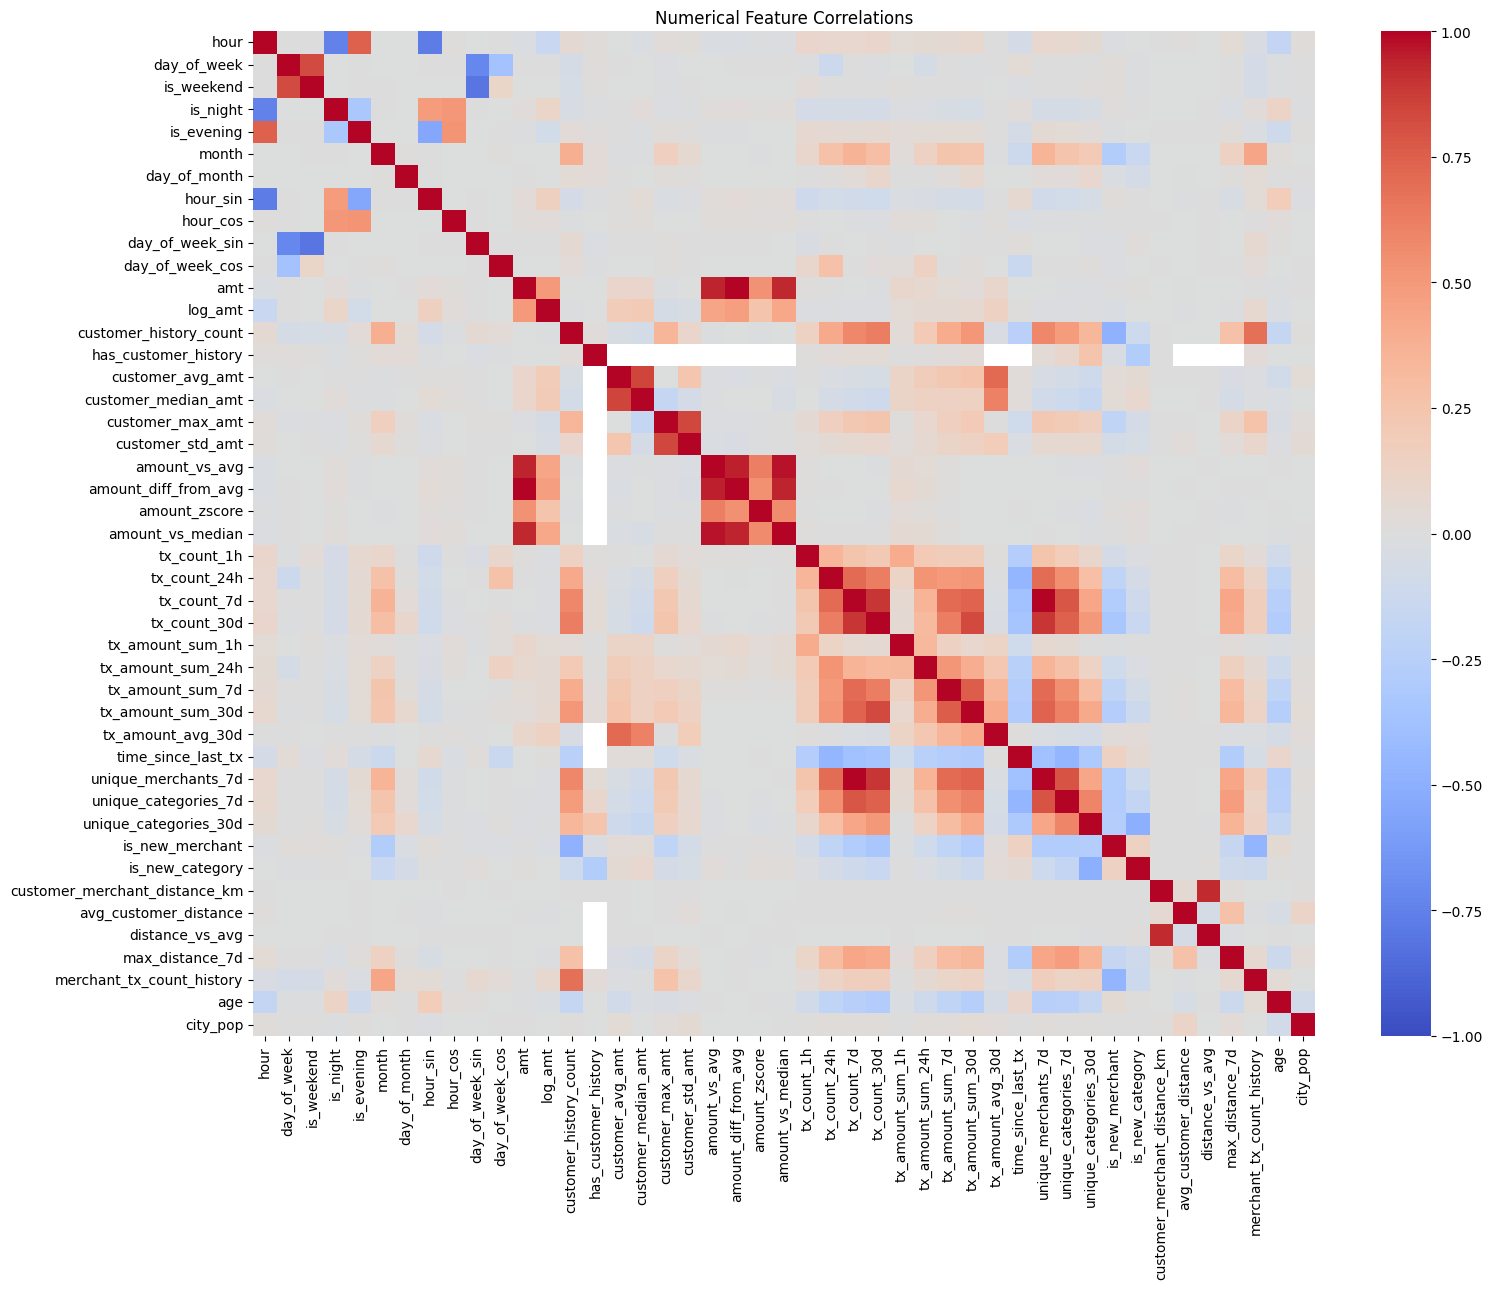

In [62]:
numeric_features = features.select_dtypes(include='number')
correlation = numeric_features.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(correlation, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Numerical Feature Correlations')
plt.tight_layout()
plt.show()

# 4. Feature Selection

In [63]:
ordered = df.sort_values('row_id').reset_index(drop=True)
timestamps = ordered['trans_date_trans_time']
sorted_timestamps = timestamps.sort_values().reset_index(drop=True)
validation_start = sorted_timestamps.iloc[int(len(ordered) * 0.70)]
test_start = sorted_timestamps.iloc[int(len(ordered) * 0.85)]
train_index = ordered.index[timestamps < validation_start]
validation_index = ordered.index[(timestamps >= validation_start) & (timestamps < test_start)]
test_index = ordered.index[timestamps >= test_start]

if min(len(train_index), len(validation_index), len(test_index)) == 0:
    raise ValueError('Chronological split produced an empty partition; check timestamp distribution.')

X_train = features.loc[train_index].copy()
y_train = ordered.loc[train_index, 'is_fraud']

if len(y_train.value_counts()) != 2 or y_train.value_counts().min() < 2:
    raise ValueError('Mutual information requires both fraud classes with at least two training examples each.')

display(pd.DataFrame({
    'split': ['Train', 'Validation', 'Test'],
    'transactions': [len(train_index), len(validation_index), len(test_index)],
    'start': [timestamps.loc[index].min() for index in [train_index, validation_index, test_index]],
    'end': [timestamps.loc[index].max() for index in [train_index, validation_index, test_index]],
}))

,split,transactions,start,end
0,Train,1296675,2019-01-01 00:00:18,2020-06-21 12:13:37
1,Validation,277859,2020-06-21 12:14:25,2020-10-03 00:58:23
2,Test,277860,2020-10-03 00:59:48,2020-12-31 23:59:34


### Training-Only Quality Filters

In [64]:
MISSING_REVIEW = 0.60
MISSING_LIMIT = 0.80
VARIANCE_LIMIT = 0.01
CORRELATION_LIMIT = 0.95
N_FEATURES = 15

quality_report, removed, filtered_features = quality_filter(
    X_train, MISSING_REVIEW, MISSING_LIMIT, VARIANCE_LIMIT, CORRELATION_LIMIT
)
display(quality_report.sort_values('missing_pct', ascending=False))
print(f'Features after quality filters: {len(filtered_features)} of {len(X_train.columns)}')
display(pd.DataFrame(removed, columns=['feature', 'reason']))

,feature,missing_pct,review_missing
18,customer_std_amt,0.151619,False
21,amount_zscore,0.151619,False
41,max_distance_7d,0.097789,False
15,customer_avg_amt,0.075809,False
20,amount_diff_from_avg,0.075809,False
19,amount_vs_avg,0.075809,False
32,time_since_last_tx,0.075809,False
22,amount_vs_median,0.075809,False
39,avg_customer_distance,0.075809,False
17,customer_max_amt,0.075809,False


Features after quality filters: 44 of 49


,feature,reason
0,has_customer_history,variance <= 0.01
1,is_new_category,variance <= 0.01
2,amount_diff_from_avg,correlation > 0.95 with amt
3,amount_vs_median,correlation > 0.95 with amount_vs_avg
4,unique_merchants_7d,correlation > 0.95 with tx_count_7d


### Mutual Information

In [65]:
mi_scores, selected_features = mutual_information_selection(
    X_train, y_train, filtered_features, N_FEATURES
)
display(mi_scores)
print('Selected features:', selected_features)

X_train_selected = features.loc[train_index, selected_features].copy()
X_validation_selected = features.loc[validation_index, selected_features].copy()
X_test_selected = features.loc[test_index, selected_features].copy()
y_validation = ordered.loc[validation_index, 'is_fraud']
y_test = ordered.loc[test_index, 'is_fraud']

,feature,mutual_information
0,max_distance_7d,0.024273
1,log_amt,0.017390
2,amt,0.017368
3,age,0.016606
4,tx_amount_sum_24h,0.012857
5,amount_vs_avg,0.011525
6,customer_max_amt,0.011091
7,amount_zscore,0.010825
8,tx_amount_sum_1h,0.008379
9,hour,0.005178


Selected features: ['max_distance_7d', 'log_amt', 'amt', 'age', 'tx_amount_sum_24h', 'amount_vs_avg', 'customer_max_amt', 'amount_zscore', 'tx_amount_sum_1h', 'hour', 'tx_amount_avg_30d', 'hour_cos', 'city_pop', 'customer_median_amt', 'tx_amount_sum_7d']
